#import libraries

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [69]:
##Load dataset
df = pd.read_csv("../data/raw/supply_chain_master.csv")

##Demand analysis

In [56]:
product_demand = df.groupby("Product_ID")["Units_Sold"].agg(
    ["mean", "std", "sum", "min", "max"]
)

product_demand.head()
top_products = (
    df.groupby(["Product_ID", "Product_Name"])["Units_Sold"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_products

low_demand_products = (
    df.groupby(["Product_ID", "Product_Name"])["Units_Sold"]
    .sum()
    .sort_values()
    .head(10)
)

low_demand_products
df["Date"] = pd.to_datetime(df["Date"])
monthly_demand = (
    df.groupby(df["Date"].dt.month)["Units_Sold"]
    .mean()
)

monthly_demand

Date
1     42.636852
2     42.838468
3     45.009419
4     44.102773
5     45.945523
6     47.228213
7     44.991381
8     46.798865
9     48.503440
10    51.926400
11    59.321120
12    63.970890
Name: Units_Sold, dtype: float64

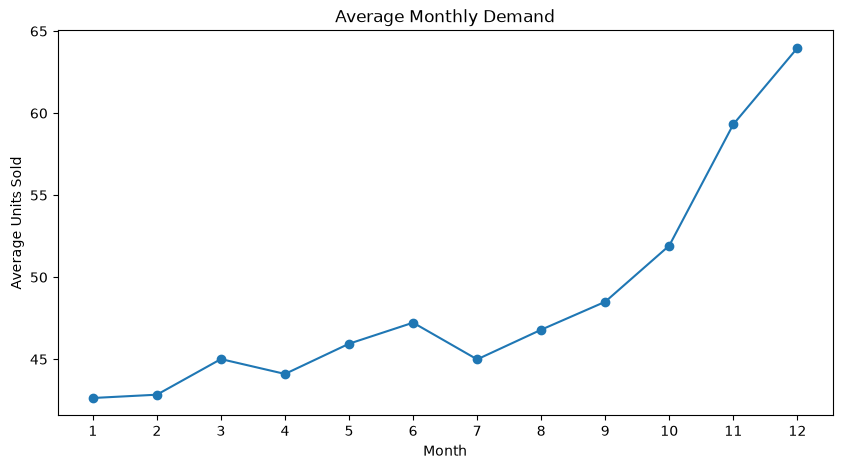

In [57]:
plt.figure(figsize=(10, 5))

monthly_demand.plot(kind="line", marker="o")

plt.title("Average Monthly Demand")
plt.xlabel("Month")
plt.ylabel("Average Units Sold")
plt.xticks(range(1, 13))

plt.show()

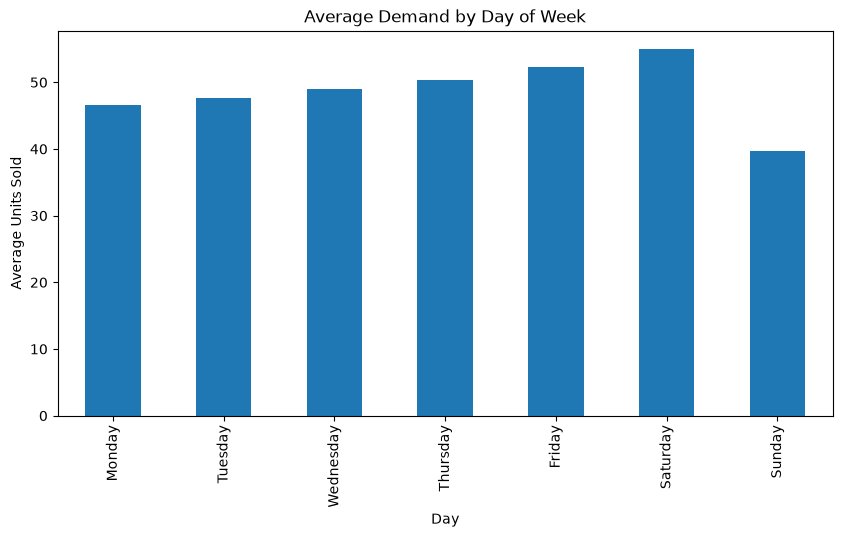

In [58]:
weekly_demand = (
    df.groupby(df["Date"].dt.day_name())["Units_Sold"]
    .mean()
)
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekly_demand = weekly_demand.reindex(day_order)

weekly_demand

plt.figure(figsize=(10, 5))

weekly_demand.plot(kind="bar")

plt.title("Average Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average Units Sold")

plt.show()

In [59]:
yearly_demand = (
    df.groupby(df["Date"].dt.year)["Units_Sold"]
    .sum()
)

yearly_demand

Date
2021    4036004
2022    4241571
2023    4432616
2024    4649397
2025    4843375
Name: Units_Sold, dtype: int64

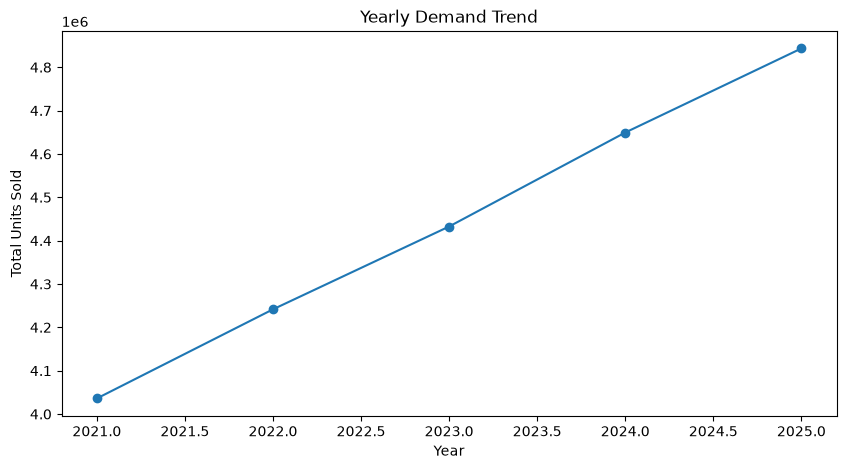

In [60]:
plt.figure(figsize=(10, 5))

yearly_demand.plot(kind="line", marker="o")

plt.title("Yearly Demand Trend")
plt.xlabel("Year")
plt.ylabel("Total Units Sold")

plt.show()

##Inventory analysis

In [61]:
average_inventory = df["Inventory_Level"].mean()

print("Average Inventory:", round(average_inventory, 2))

inventory_by_product = (
    df.groupby(["Product_ID", "Product_Name"])["Inventory_Level"]
    .mean()
    .sort_values(ascending=False)
)

inventory_by_product.head(10)

df["Inventory_Value"] = (
    df["Inventory_Level"] * df["Unit_Cost"]
)

total_cogs = df["COGS"].sum()

average_inventory_value = df["Inventory_Value"].mean()

inventory_turnover = (
    total_cogs / average_inventory_value
)

print("Inventory Turnover:", round(inventory_turnover, 2))

stockout_count = df["Stockout_Flag"].sum()

print("Stockout Events:", stockout_count)
stockout_rate = (
    df["Stockout_Flag"].mean() * 100
)

print(
    "Stockout Rate:",
    round(stockout_rate, 2),
    "%"
)

stockouts_by_product = (
    df.groupby(
        ["Product_ID", "Product_Name"]
    )["Stockout_Flag"]
    .sum()
    .sort_values(ascending=False)
)

stockouts_by_product.head(10)

Average Inventory: 468.74
Inventory Turnover: 43702.12
Stockout Events: 6497
Stockout Rate: 1.42 %


Product_ID  Product_Name   
P027        Tea                344
P044        Washing Machine    336
P003        Keyboard           279
P050        Table              276
P035        Tablet             222
P012        Microwave          211
P034        Mouse              186
P011        Refrigerator       183
P004        Mouse              178
P025        Calculator         174
Name: Stockout_Flag, dtype: int64

##Supplier analysis

In [62]:
supplier_delivery = (
    df.dropna(subset=["Delivery_Days"])
    .groupby("Supplier_ID")["Delivery_Days"]
    .agg(["mean", "min", "max", "std", "count"])
)

supplier_delivery

df["Late_Delivery_Flag"] = (
    df["Delivery_Days"] >
    df["Lead_Time_Days"]
).astype(int)

late_deliveries = (
    df.groupby("Supplier_ID")["Late_Delivery_Flag"]
    .sum()
    .sort_values(ascending=False)
)

late_deliveries


Supplier_ID
S08    4850
S09    3910
S05    3869
S01    3259
S06    2816
S07    2702
S10    1699
S03    1651
S02    1639
S04    1092
Name: Late_Delivery_Flag, dtype: int64

In [63]:
supplier_performance = (
    df.dropna(subset=["Delivery_Days"])
    .groupby("Supplier_ID")
    .agg(
        Total_Orders=("Order_Quantity", "count"),
        Avg_Delivery_Days=("Delivery_Days", "mean"),
        Avg_Lead_Time=("Lead_Time_Days", "mean"),
        Late_Deliveries=("Late_Delivery_Flag", "sum")
    )
)

supplier_performance["On_Time_Rate"] = (
    1 -
    supplier_performance["Late_Deliveries"] /
    supplier_performance["Total_Orders"]
) * 100

supplier_performance.sort_values(
    "On_Time_Rate",
    ascending=False
)

,Total_Orders,Avg_Delivery_Days,Avg_Lead_Time,Late_Deliveries,On_Time_Rate
Supplier_ID,,,,,
S04,1693,14.943296,13.500886,1092,35.499114
S03,2510,12.182072,10.704382,1651,34.223108
S05,5880,9.380952,7.895748,3869,34.200680
S08,7309,11.619373,10.119031,4850,33.643453
S06,4233,10.300969,8.816678,2816,33.475077
S09,5845,10.657827,9.144910,3910,33.105218
S02,2447,11.787904,10.259093,1639,33.020025
S07,4027,11.039235,9.530668,2702,32.902905
S10,2530,13.552964,12.024111,1699,32.845850


##Correlation analysis

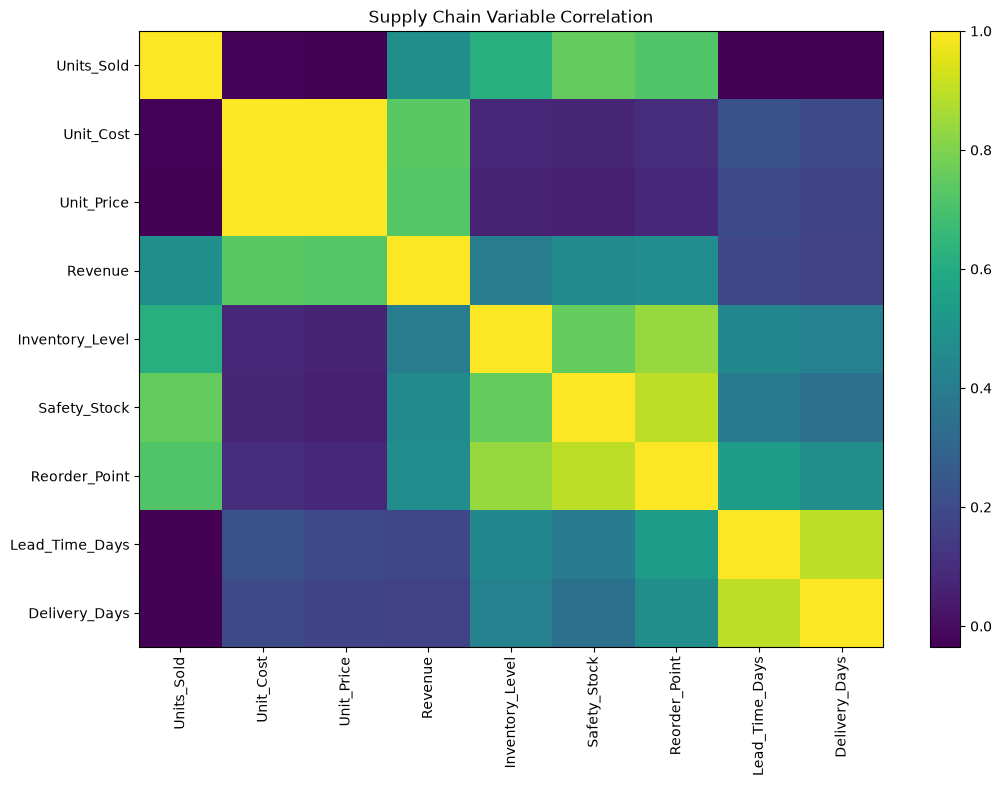

In [70]:
numeric_columns = [
    "Units_Sold",
    "Unit_Cost",
    "Unit_Price",
    "Revenue",
    "Inventory_Level",
    "Safety_Stock",
    "Reorder_Point",
    "Lead_Time_Days",
    "Delivery_Days"
]

correlation = df[numeric_columns].corr()

correlation

plt.figure(figsize=(12, 8))

plt.imshow(
    correlation,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Supply Chain Variable Correlation")

plt.show()

## Key Findings

1. Demand increased between 2021 and 2025.

2. November and December showed higher average demand.

3. Several products had significantly higher demand volatility.

4. Some products experienced frequent stockouts.

5. Supplier delivery times varied considerably.

6. Products with high demand volatility require higher safety stock.